# equipo_proyecto_avance4

Comparación de una red totalmente conectada de referencia, la CNN original y la CNN con dos convoluciones adicionales. Diagnóstico de sobreajuste y regularización.

**Procedencia:** los experimentos se ejecutaron desde este repositorio con DirectML en una Radeon RX 6700S. La MLP es una referencia reconstruida y no el modelo histórico identificado del Avance 3. Las métricas corresponden a validación, no a un test independiente.

Las figuras se conservan en PNG y PDF; los históricos, matrices y predicciones se guardan en CSV. Para volver a entrenar, use una carpeta nueva de salida y active `RUN_TRAINING`.

In [1]:
from pathlib import Path
import sys, json, inspect, subprocess
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/model.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / "reports/avance4_2026-10-21"
RUN_TRAINING = False
print("Proyecto:", ROOT)
print("Evidencia de ejecuciones:", OUTPUT)

Proyecto: C:\Users\andre\Documents\Tec escuela\redes neuronales\NeuralNetworksTeamEnvironment
Evidencia de ejecuciones: C:\Users\andre\Documents\Tec escuela\redes neuronales\NeuralNetworksTeamEnvironment\reports\avance4_2026-10-21


## 1. Datos y protocolo

Se usan 12,753 imágenes de entrenamiento y 3,712 de validación, 104 clases, resolución efectiva 112×112, lote 64 y semilla 0. Las etiquetas son enteras y los píxeles se normalizan a [0,1]. Solo entrenamiento usa aumentos. El mejor checkpoint se selecciona por F1 macro. Las dos CNN sin la intervención adicional usan Adam a 1e-3, dropout 0.5 y paciencia 5. La MLP usa Adam a 1e-4, paciencia 10 y mínimo 10 épocas, tras el colapso del primer intento a 1e-3. Ese ensayo se conserva en diagnósticos. La intervención combinada usa AdamW, reducción del LR y paciencia 12.

Una sola semilla no permite afirmar significancia estadística. La validación usada para selección no es un test final independiente.

In [2]:
from src.config import load_config
cfg = load_config(OUTPUT / "cnn_original.yaml")
display({"data": cfg["data"], "train": cfg["train"], "runtime": cfg["runtime"]})
for key in ["cnn_original", "cnn_dos_capas_extra", "cnn_regularizada", "mlp_referencia"]:
    profile = load_config(OUTPUT / f"{key}.yaml")
    display({"experiment": key, "model": profile.get("model", {"architecture": "baseline"}), "train": profile["train"]})
manifest = json.loads((OUTPUT / "manifest.json").read_text(encoding="utf-8"))
print("Commit:", manifest["git_commit"])
print("Checkpoint elegido por:", manifest["selection_metric"])

{'data': {'img_size': 112,
  'num_classes': 104,
  'batch_size': 64,
  'cache': 'ram'},
 'train': {'lr': 0.001,
  'epochs_full': 150,
  'epochs_small': 300,
  'eval_every_small': 10,
  'patience': 5},
 'runtime': {'backend': 'directml', 'input_pipeline': 'dlpack_prefetch'}}

{'experiment': 'cnn_original',
 'model': {'architecture': 'baseline'},
 'train': {'lr': 0.001,
  'epochs_full': 150,
  'epochs_small': 300,
  'eval_every_small': 10,
  'patience': 5}}

{'experiment': 'cnn_dos_capas_extra',
 'model': {'architecture': 'deep'},
 'train': {'lr': 0.001,
  'epochs_full': 150,
  'epochs_small': 300,
  'eval_every_small': 10,
  'patience': 5}}

{'experiment': 'cnn_regularizada',
 'model': {'architecture': 'baseline'},
 'train': {'optimizer': 'adamw',
  'weight_decay': 0.01,
  'lr': 0.001,
  'lr_schedule': {'type': 'plateau',
   'factor': 0.5,
   'patience': 2,
   'min_lr': 1e-05},
  'epochs_full': 150,
  'epochs_small': 300,
  'eval_every_small': 10,
  'patience': 12}}

{'experiment': 'mlp_referencia',
 'model': {'architecture': 'mlp_reference', 'hidden_units': 256},
 'train': {'lr': 0.0001,
  'epochs_full': 150,
  'epochs_small': 300,
  'eval_every_small': 10,
  'patience': 10,
  'min_epochs': 10}}

Commit: 857e6839023076d18bb4f68dc253c844b94d4dc6
Checkpoint elegido por: validation macro F1; no labeled independent test set


## 2. Código y representaciones de los modelos

La versión ampliada agrega una convolución después de pool3 y otra después de pool4. Se muestran las implementaciones reales utilizadas para entrenar, no una arquitectura ilustrativa distinta.

class FlowerCNN(nn.Module):
    """CNN original, deep o cuatro bloques Conv/BatchNorm/ReLU/Pool."""

    def __init__(self, num_classes=104, *, architecture="baseline"):
        super().__init__()
        if architecture not in EXTRA_CONV_STAGES:
            raise ValueError(f"Arquitectura desconocida: {architecture}")
        self.architecture = architecture
        channels = (3, 32, 64, 128, 256)
        self.convs = nn.ModuleList([
            nn.Conv2d(channels[i], channels[i + 1], 3, padding=1, bias=architecture != "batchnorm")
            for i in range(4)
        ])
        self.extra_convs = nn.ModuleDict({
            str(i): nn.Conv2d(FILTERS[i - 1], FILTERS[i - 1], 3, padding=1)
            for i in EXTRA_CONV_STAGES[architecture]
        })
        # PyTorch momentum es la fracción NUEVA, al contrario de Keras.
        self.batchnorms = nn.ModuleDict({
            str(i): nn.BatchNorm2d(filters, eps=BATCHNORM_EPSILON,
                                   momentum=1 - BATCHNO

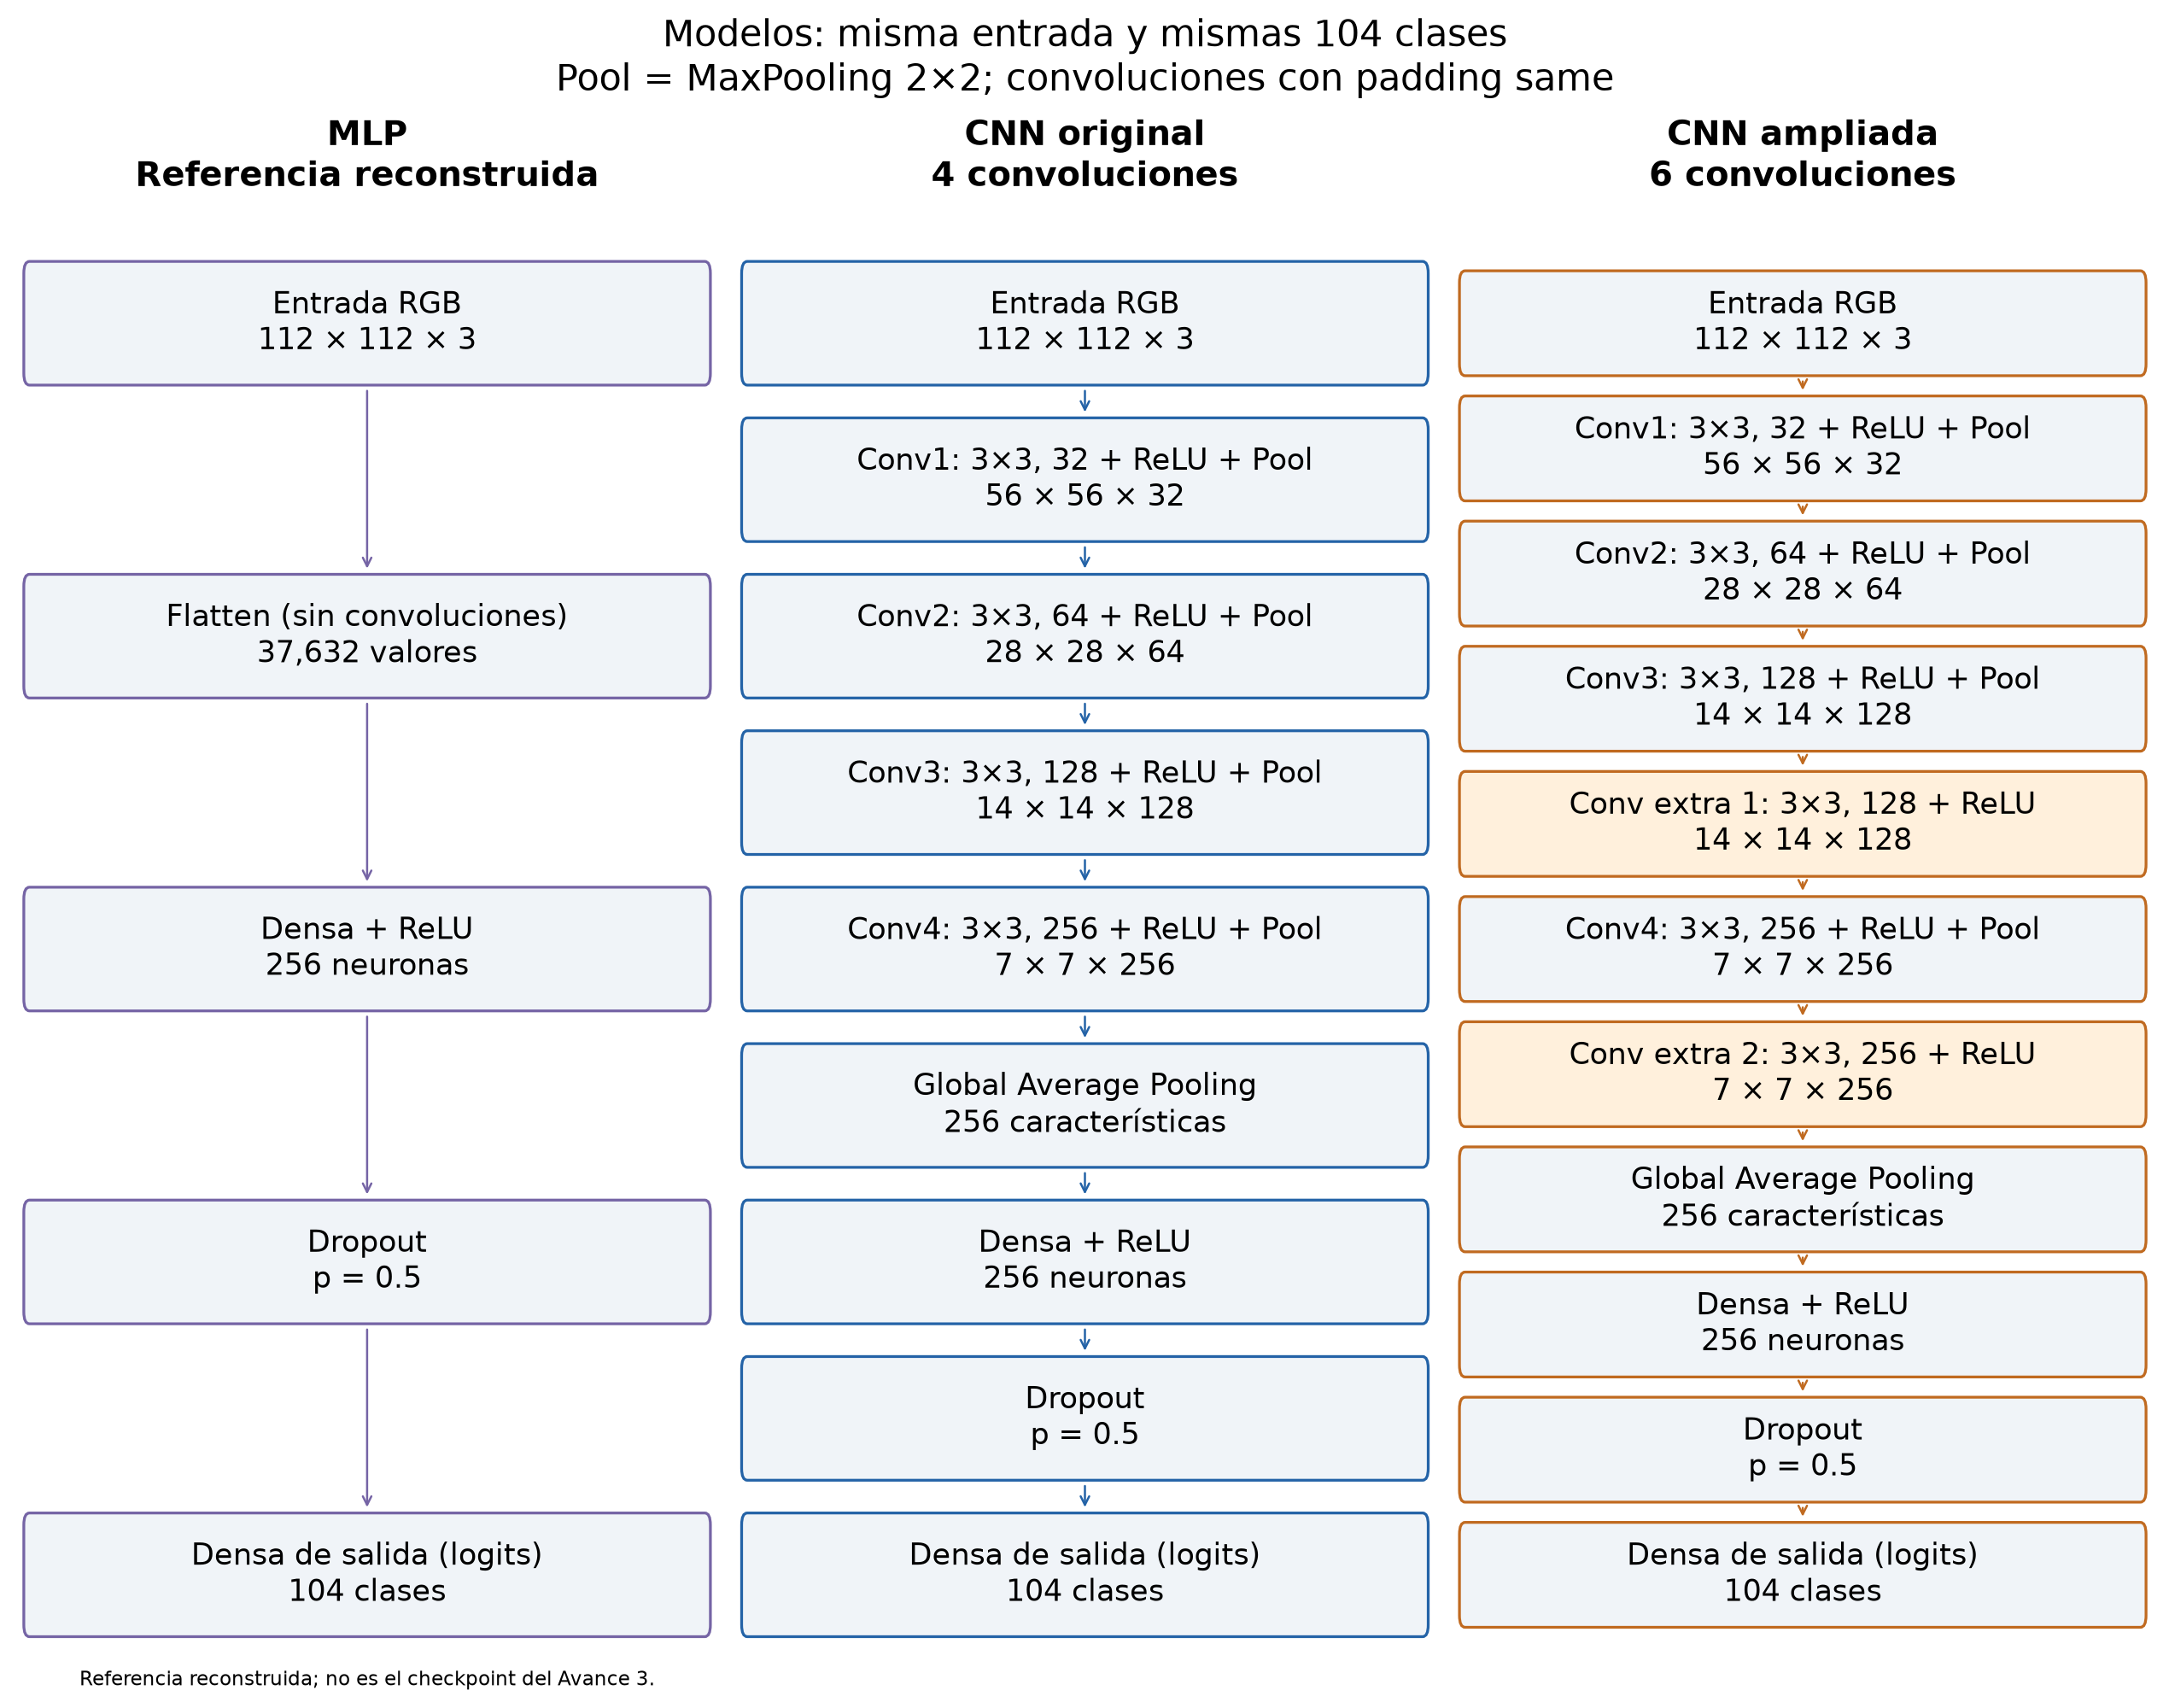

In [3]:
from src.train_directml import FlowerCNN, train_epoch, evaluate
from src.train_mlp_reference import FlowerMLP
print(inspect.getsource(FlowerCNN))
print(inspect.getsource(FlowerMLP))
display(Image(filename=str(OUTPUT / "figures/arquitecturas.png"), width=1100))

## 3. Entrenamiento reproducible

Estos comandos utilizan el mismo código que produjo los resultados guardados. Se usa una carpeta nueva para conservar las ejecuciones anteriores. Cambie `RUN_TRAINING=True` para ejecutarlos; una revisión normal del notebook carga los resultados existentes.

La CNN original y la ampliada se entrenan primero. Se añade la variante regularizada y se entrena la referencia totalmente conectada con el cargador y el ciclo existentes.

In [4]:
NEW_OUTPUT = ROOT / "reports" / "avance4_repeticion"
if RUN_TRAINING:
    subprocess.run([sys.executable, "-u", "-m", "scripts.run_avance4", "--output", str(NEW_OUTPUT)], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "-u", "-m", "src.train_mlp_reference", "--config", str(NEW_OUTPUT / "cnn_original.yaml"), "--output", str(NEW_OUTPUT), "--lr", "0.0001", "--patience", "10", "--min-epochs", "10"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "-u", "-m", "scripts.prepare_avance4", "--output", str(NEW_OUTPUT)], cwd=ROOT, check=True)
    OUTPUT = NEW_OUTPUT
else:
    print("Se cargan las ejecuciones completas; RUN_TRAINING=False.")

Se cargan las ejecuciones completas; RUN_TRAINING=False.


In [5]:
print("Ciclo de entrenamiento compartido:")
print(inspect.getsource(train_epoch))
print("Evaluación sobre imágenes sin aumentos:")
print(inspect.getsource(evaluate))

Ciclo de entrenamiento compartido:
def train_epoch(model, dataset, optimizer, device, *, sync_each_batch=False,
                input_pipeline="dlpack_prefetch"):
    """Acumula loss/accuracy en GPU y las copia una sola vez al terminar la época.

    sync_each_batch conserva el comportamiento anterior para medir el baseline.
    """
    model.train()
    loss_sum, correct = torch.zeros((), device=device), torch.zeros((), device=device)
    host_loss, host_correct, count, steps = 0.0, 0.0, 0, 0
    for images, labels in batches(dataset, device, pipeline=input_pipeline):
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()
        batch_loss = loss.detach() * len(labels)
        batch_correct = (logits.detach().argmax(dim=1) == labels).float().sum()
        if sync_each_batch:
            host_loss += batch_loss.cpu().item()
            host_correct += batch

## 4. Resultados finales y comparación

La exactitud y F1 macro pertenecen al mismo checkpoint. Se compara explícitamente MLP frente a CNN y CNN original frente a CNN con dos capas adicionales. La convolución comparte filtros y utiliza vecindarios espaciales; la MLP recibe píxeles aplanados. El aumento de profundidad no garantiza una mejora de validación.

,model,parameters,best_epoch,epochs_run,val_accuracy,val_f1_macro,val_loss,train_seconds
0,Totalmente conectada (referencia),9660776,77,87,0.155172,0.0280,3.403151,336.7
1,CNN original (4 convoluciones),480936,53,58,0.632543,0.5740,1.519583,525.8
2,CNN ampliada (6 convoluciones),1218600,46,51,0.622306,0.5502,1.785698,500.6
3,CNN original + AdamW + LR adaptable,480936,61,73,0.644397,0.5745,1.507477,605.6


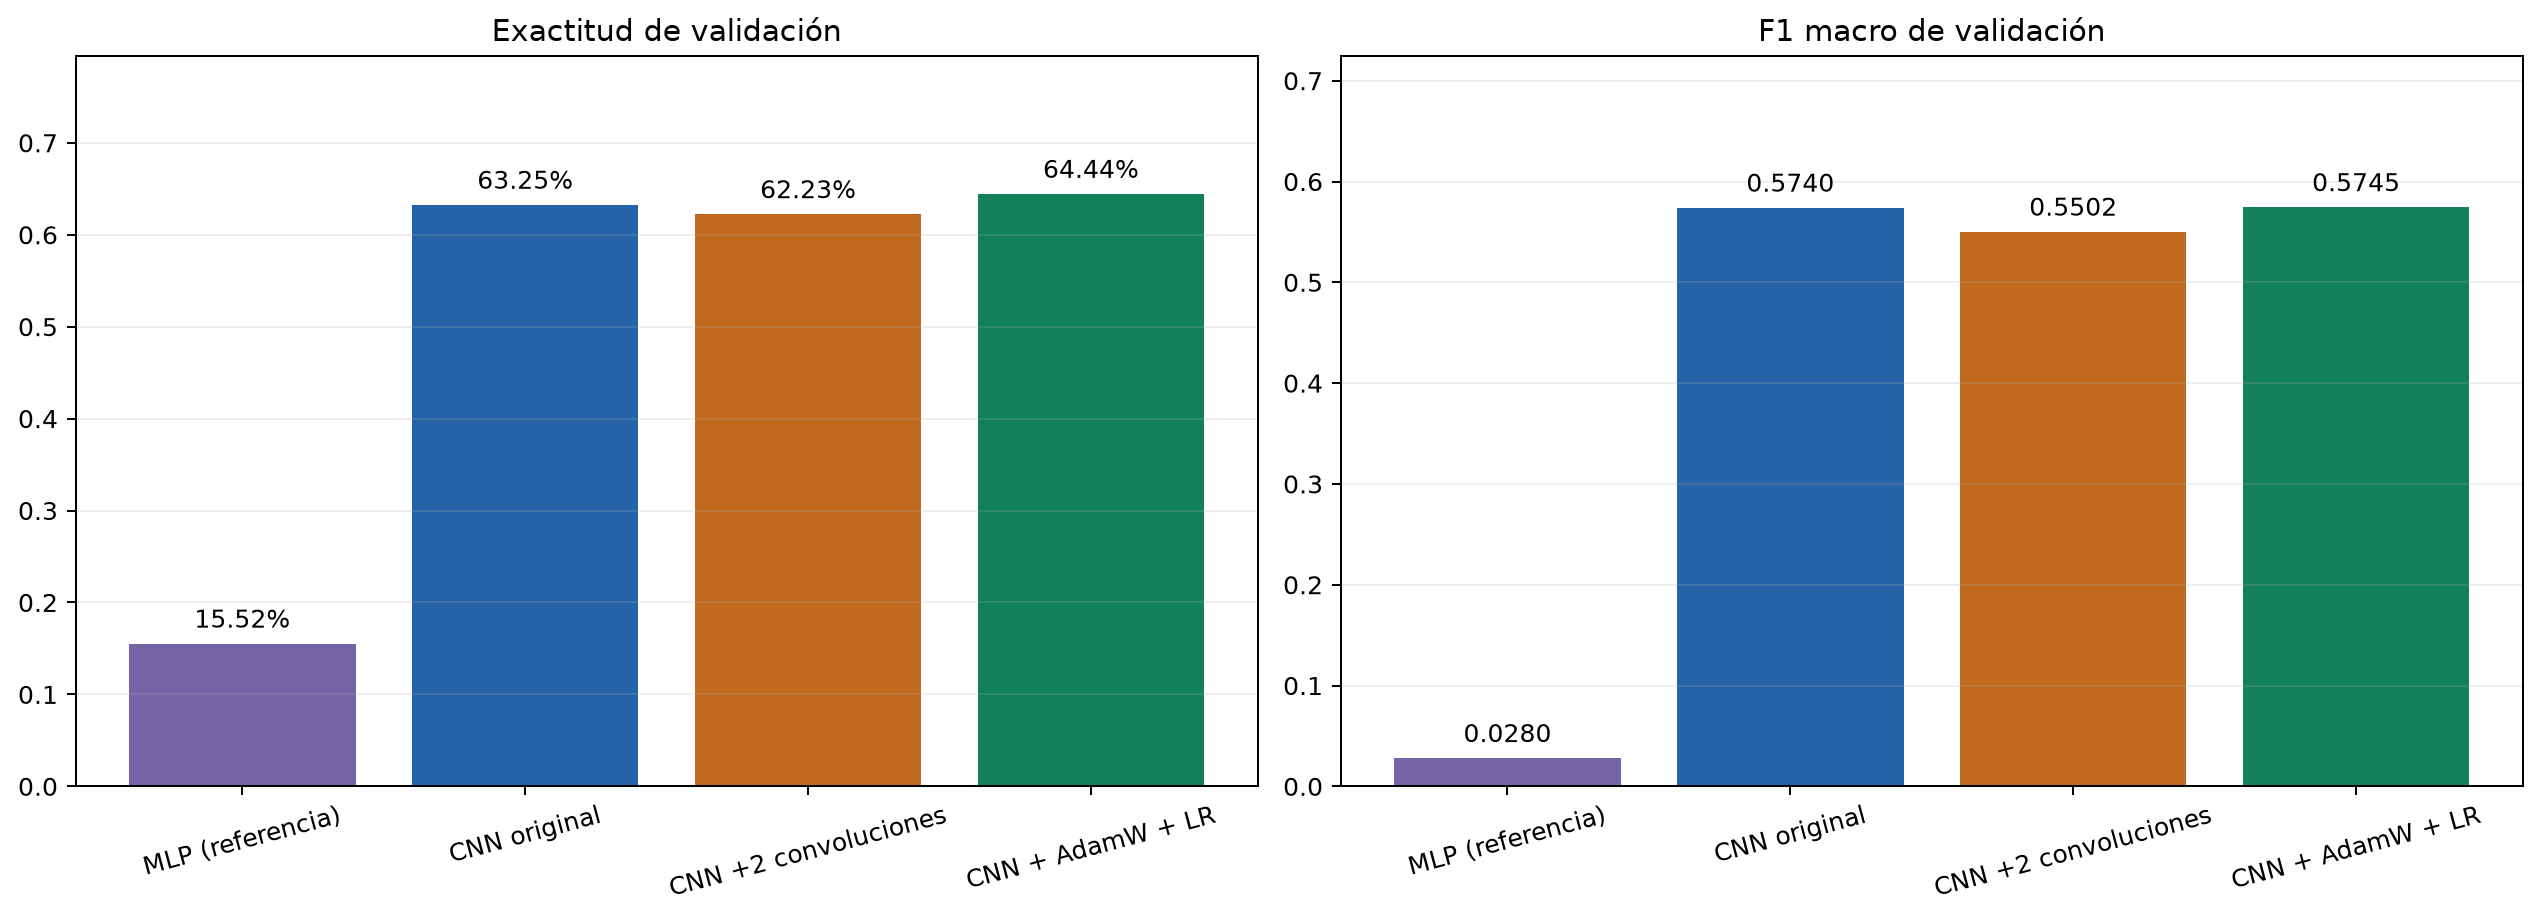

mlp_referencia -> cnn_original
Cambio de exactitud (puntos porcentuales): 47.74
Cambio de F1 macro: 0.546
cnn_original -> cnn_dos_capas_extra
Cambio de exactitud (puntos porcentuales): -1.02
Cambio de F1 macro: -0.0238
cnn_original -> cnn_regularizada
Cambio de exactitud (puntos porcentuales): 1.19
Cambio de F1 macro: 0.0005


In [6]:
results = pd.read_csv(OUTPUT / "resultados.csv")
display(results[["model", "parameters", "best_epoch", "epochs_run", "val_accuracy", "val_f1_macro", "val_loss", "train_seconds"]])
display(Image(filename=str(OUTPUT / "figures/comparacion_metricas.png"), width=1100))
indexed = results.set_index("experiment")
for reference, candidate in [("mlp_referencia", "cnn_original"), ("cnn_original", "cnn_dos_capas_extra"), ("cnn_original", "cnn_regularizada")]:
    print(reference, "->", candidate)
    print("Cambio de exactitud (puntos porcentuales):", round(100*(indexed.loc[candidate,"val_accuracy"]-indexed.loc[reference,"val_accuracy"]),2))
    print("Cambio de F1 macro:", round(indexed.loc[candidate,"val_f1_macro"]-indexed.loc[reference,"val_f1_macro"],4))

## 5. Diagnóstico de sobreajuste y regularización

Se comparan pérdida y exactitud de entrenamiento frente a validación. Una pérdida de entrenamiento que disminuye mientras validación se estanca o empeora es evidencia de sobreajuste. Entrenamiento se mide con aumentos y dropout, por lo que una diferencia puntual de exactitudes no basta para diagnosticarlo.

Dropout, aumentos y parada temprana están presentes en todos los modelos. La intervención adicional combina AdamW (weight decay 0.01, sin sesgos), reducción del LR por factor 0.5 con paciencia 2, mínimo 1e-5 y parada temprana con paciencia 12. El experimento mide el efecto combinado, no el aporte aislado de cada técnica.

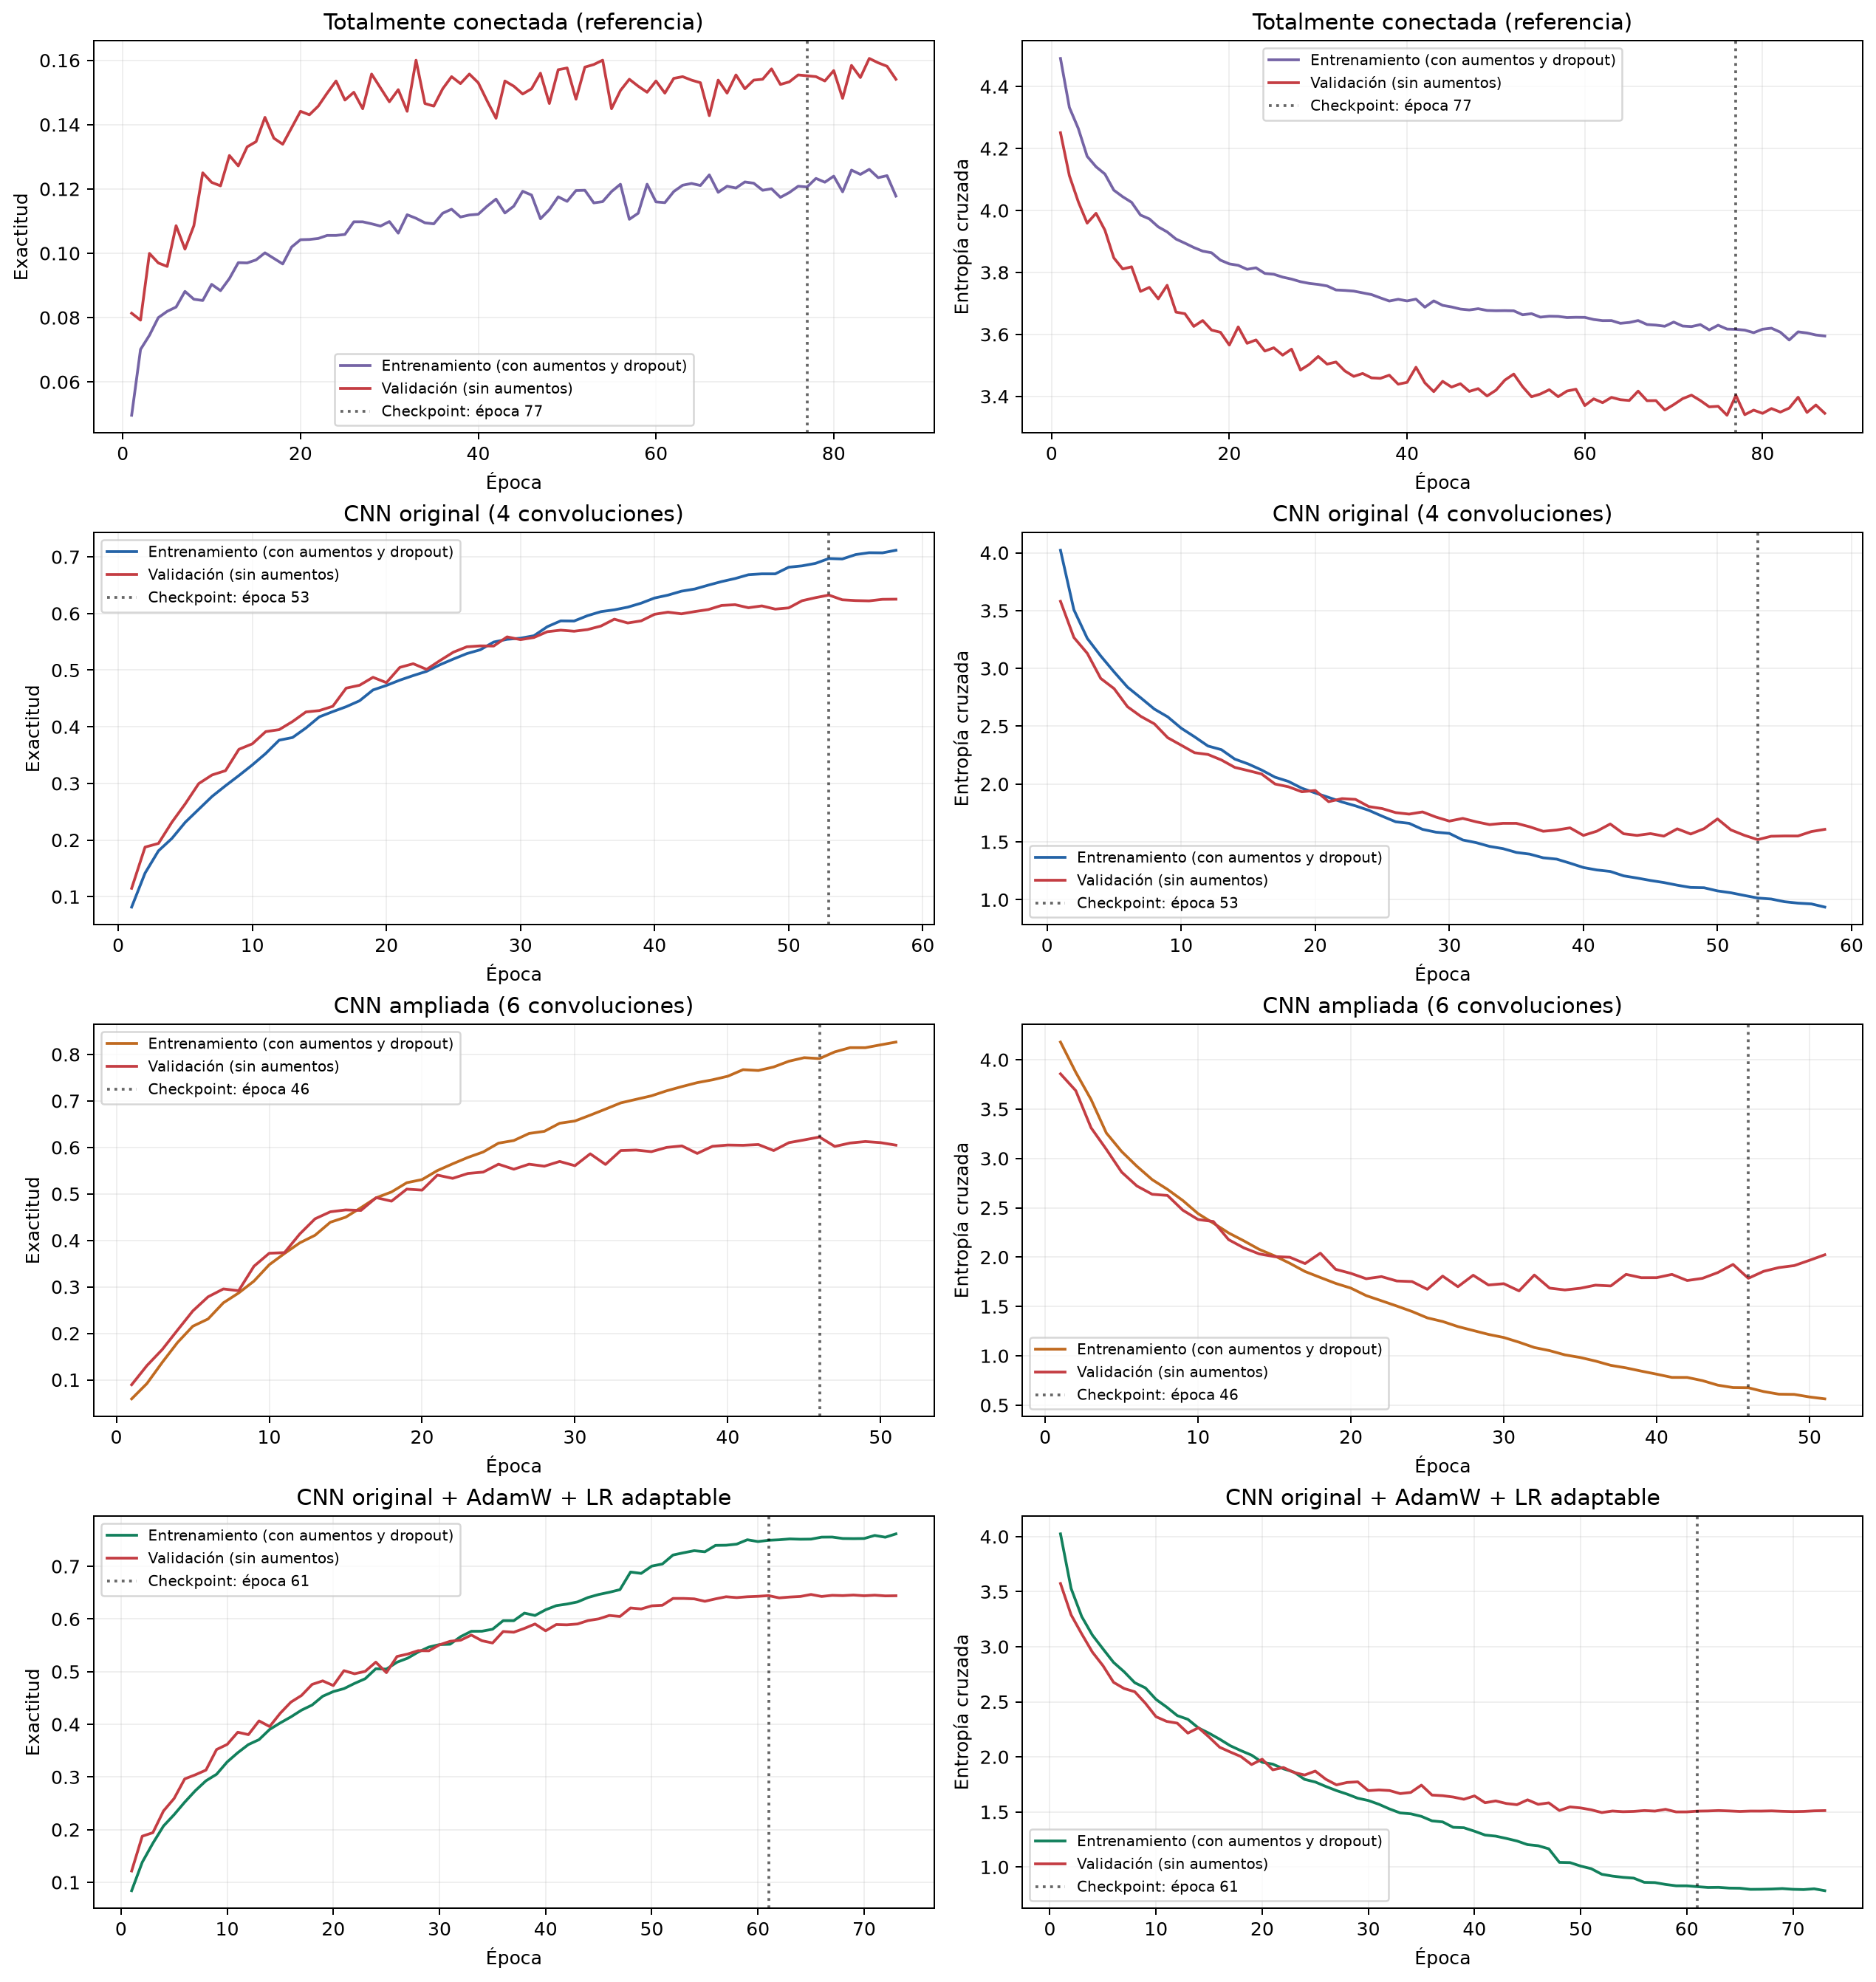

,model,train_accuracy_at_checkpoint,val_accuracy,accuracy_gap_at_checkpoint
0,Totalmente conectada (referencia),0.120599,0.155172,-0.034573
1,CNN original (4 convoluciones),0.697091,0.632543,0.064548
2,CNN ampliada (6 convoluciones),0.791030,0.622306,0.168724
3,CNN original + AdamW + LR adaptable,0.749471,0.644397,0.105074


Totalmente conectada (referencia) | mínima pérdida val: 3.3389 en época 76 | última pérdida train/val: 3.5948 3.3452
CNN original (4 convoluciones) | mínima pérdida val: 1.5196 en época 53 | última pérdida train/val: 0.9365 1.6085
CNN ampliada (6 convoluciones) | mínima pérdida val: 1.6582 en época 31 | última pérdida train/val: 0.564 2.0241
CNN original + AdamW + LR adaptable | mínima pérdida val: 1.4943 en época 52 | última pérdida train/val: 0.7851 1.512


In [7]:
display(Image(filename=str(OUTPUT / "figures/comparacion_curvas.png"), width=1000))
display(results[["model", "train_accuracy_at_checkpoint", "val_accuracy", "accuracy_gap_at_checkpoint"]])
for row in results.itertuples():
    run_dir = next((OUTPUT / "runs" / row.experiment).glob("*/summary.json")).parent
    history = pd.read_csv(run_dir / "history.csv")
    best_loss = history.loc[history.val_loss.idxmin()]
    print(row.model, "| mínima pérdida val:", round(best_loss.val_loss,4), "en época", int(best_loss.epoch)+1,
          "| última pérdida train/val:", round(history.iloc[-1].loss,4), round(history.iloc[-1].val_loss,4))

## 6. Modelo elegido, matrices de confusión y errores

Se elige el mayor F1 macro de validación. La matriz normalizada muestra recall en la diagonal (filas reales, columnas predichas). Los ejemplos muestran seis aciertos y seis errores elegidos con semilla fija; esa selección ilustrativa no representa la frecuencia de errores del modelo.

Modelo elegido: CNN original + AdamW + LR adaptable | F1 macro: 0.5745 | exactitud: 0.6443965517241379


,true,pred,count
0,common tulip,rose,12
1,carnation,rose,12
2,anthurium,rose,10
3,windflower,wild rose,8
4,wild rose,windflower,8
5,daisy,common dandelion,8
6,camellia,rose,8
7,rose,wild rose,7
8,wild rose,wild geranium,7
9,common dandelion,daisy,7


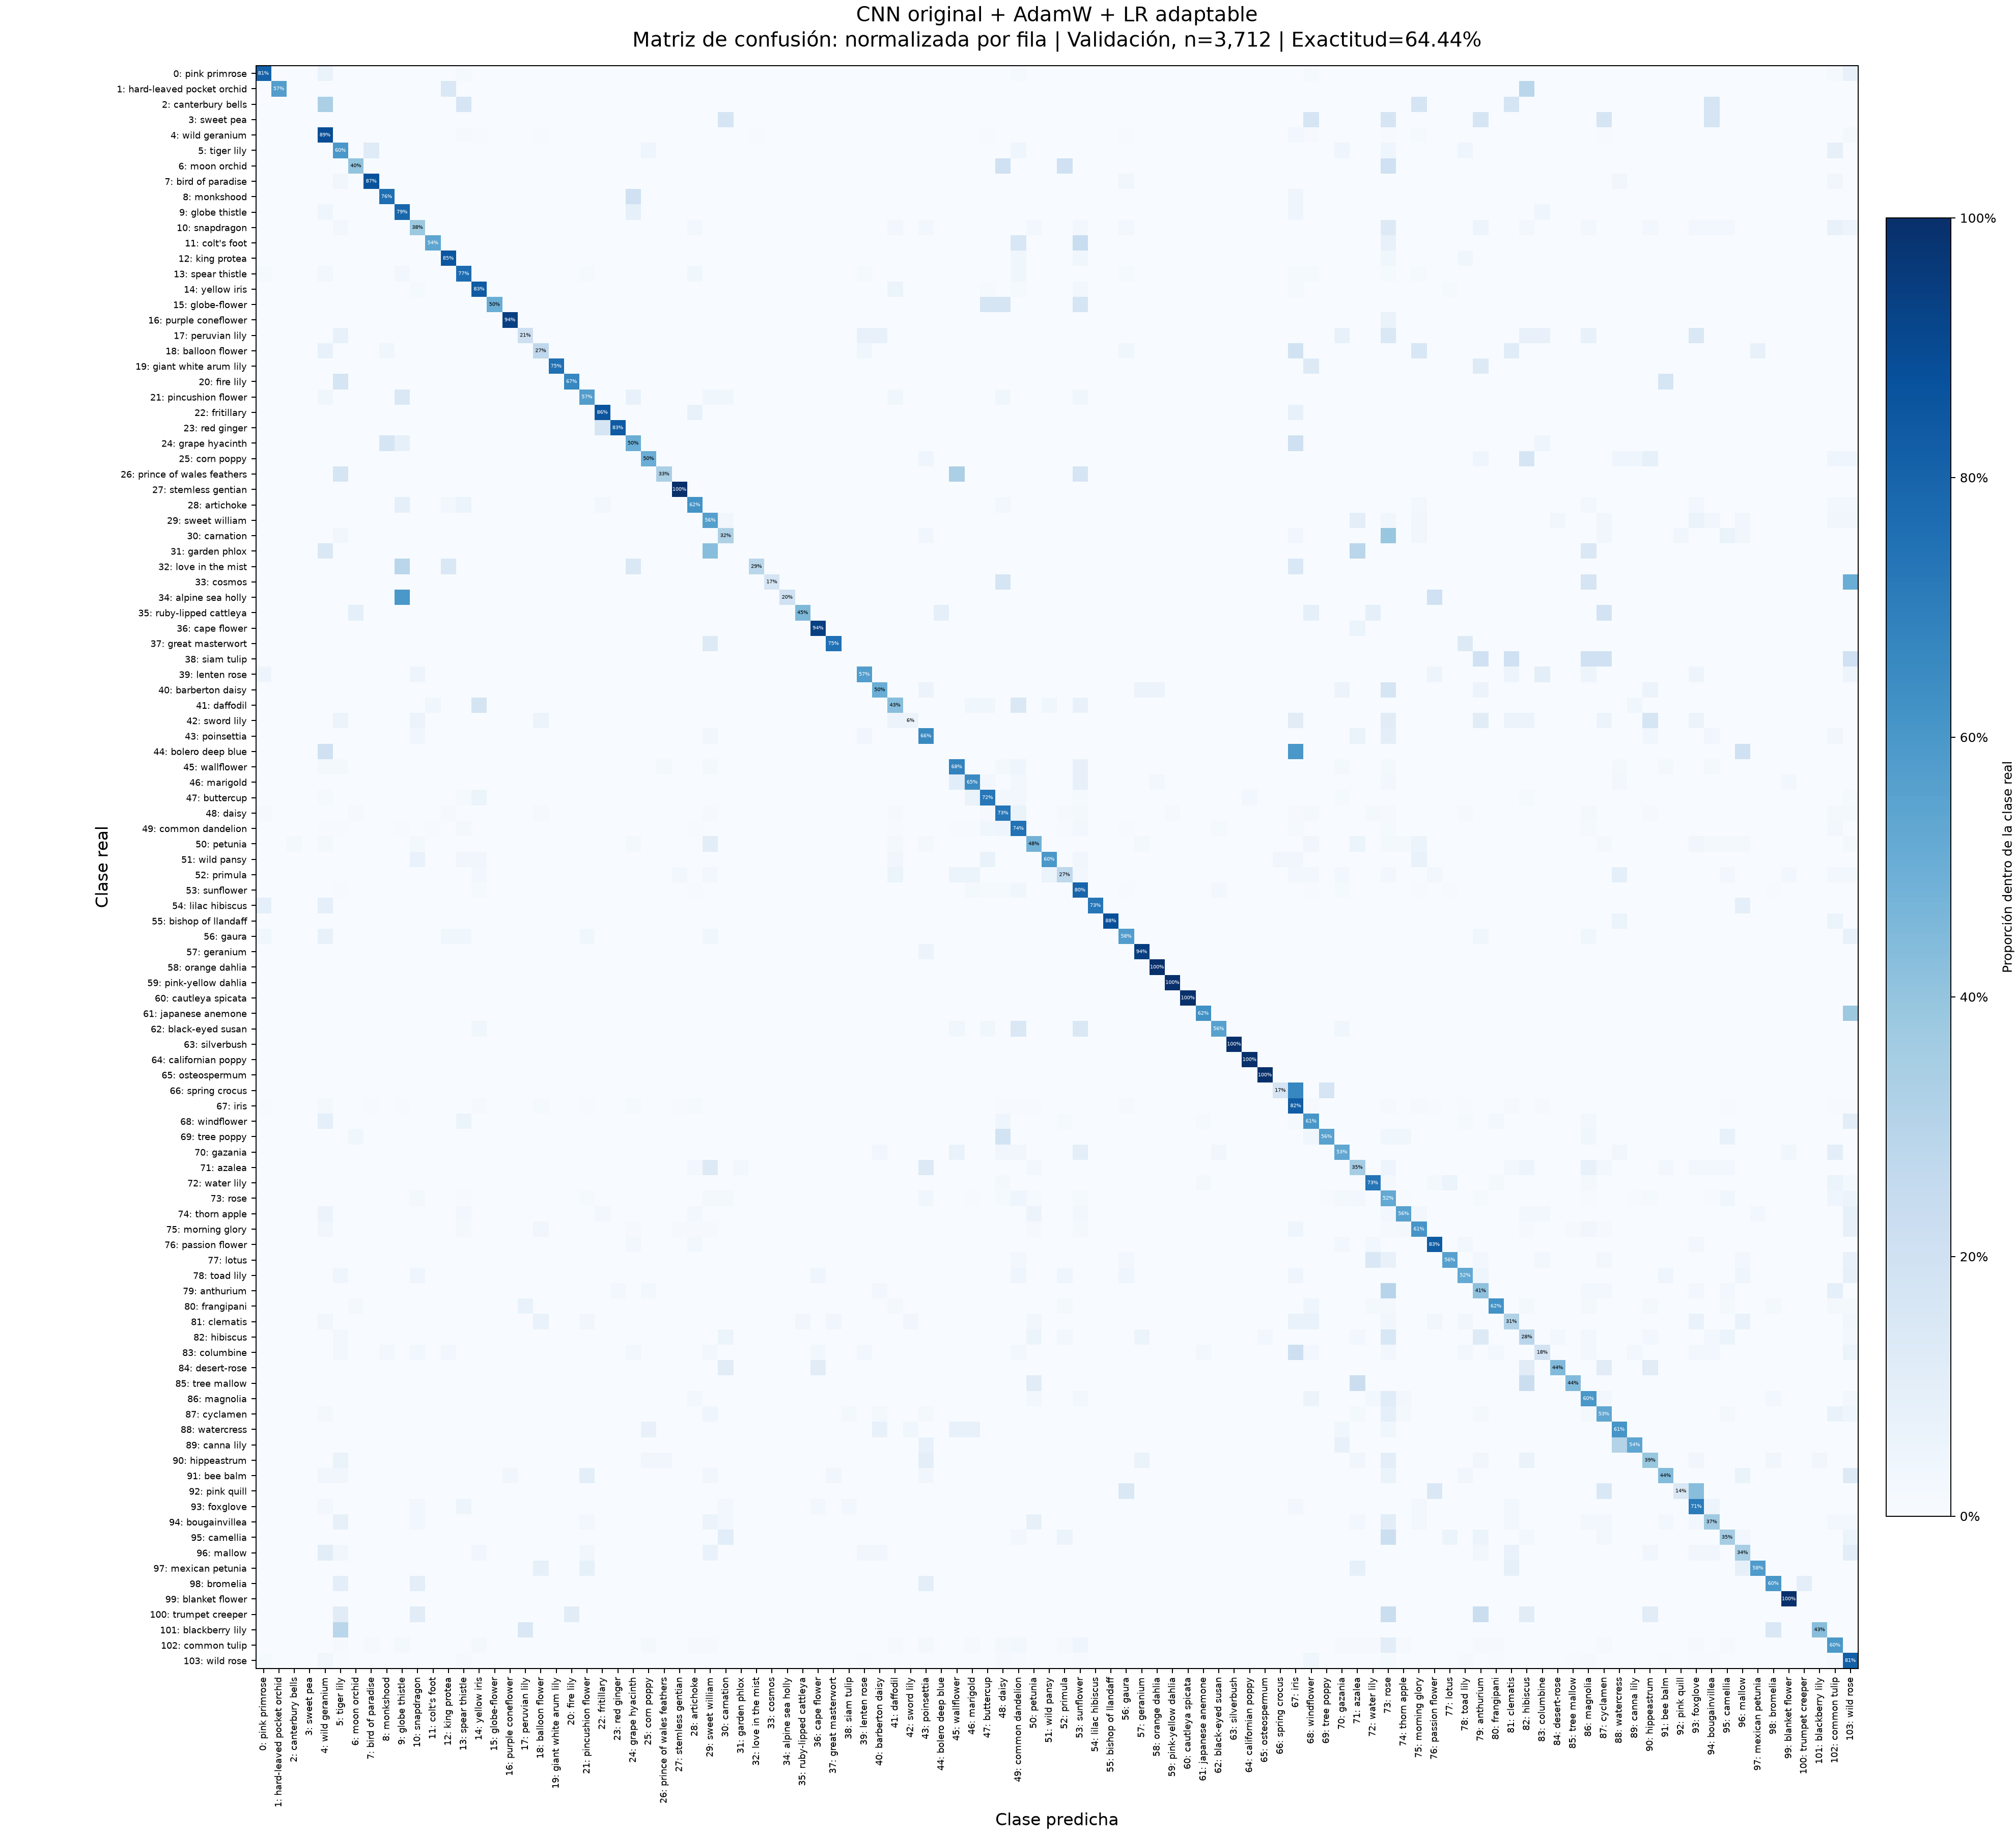

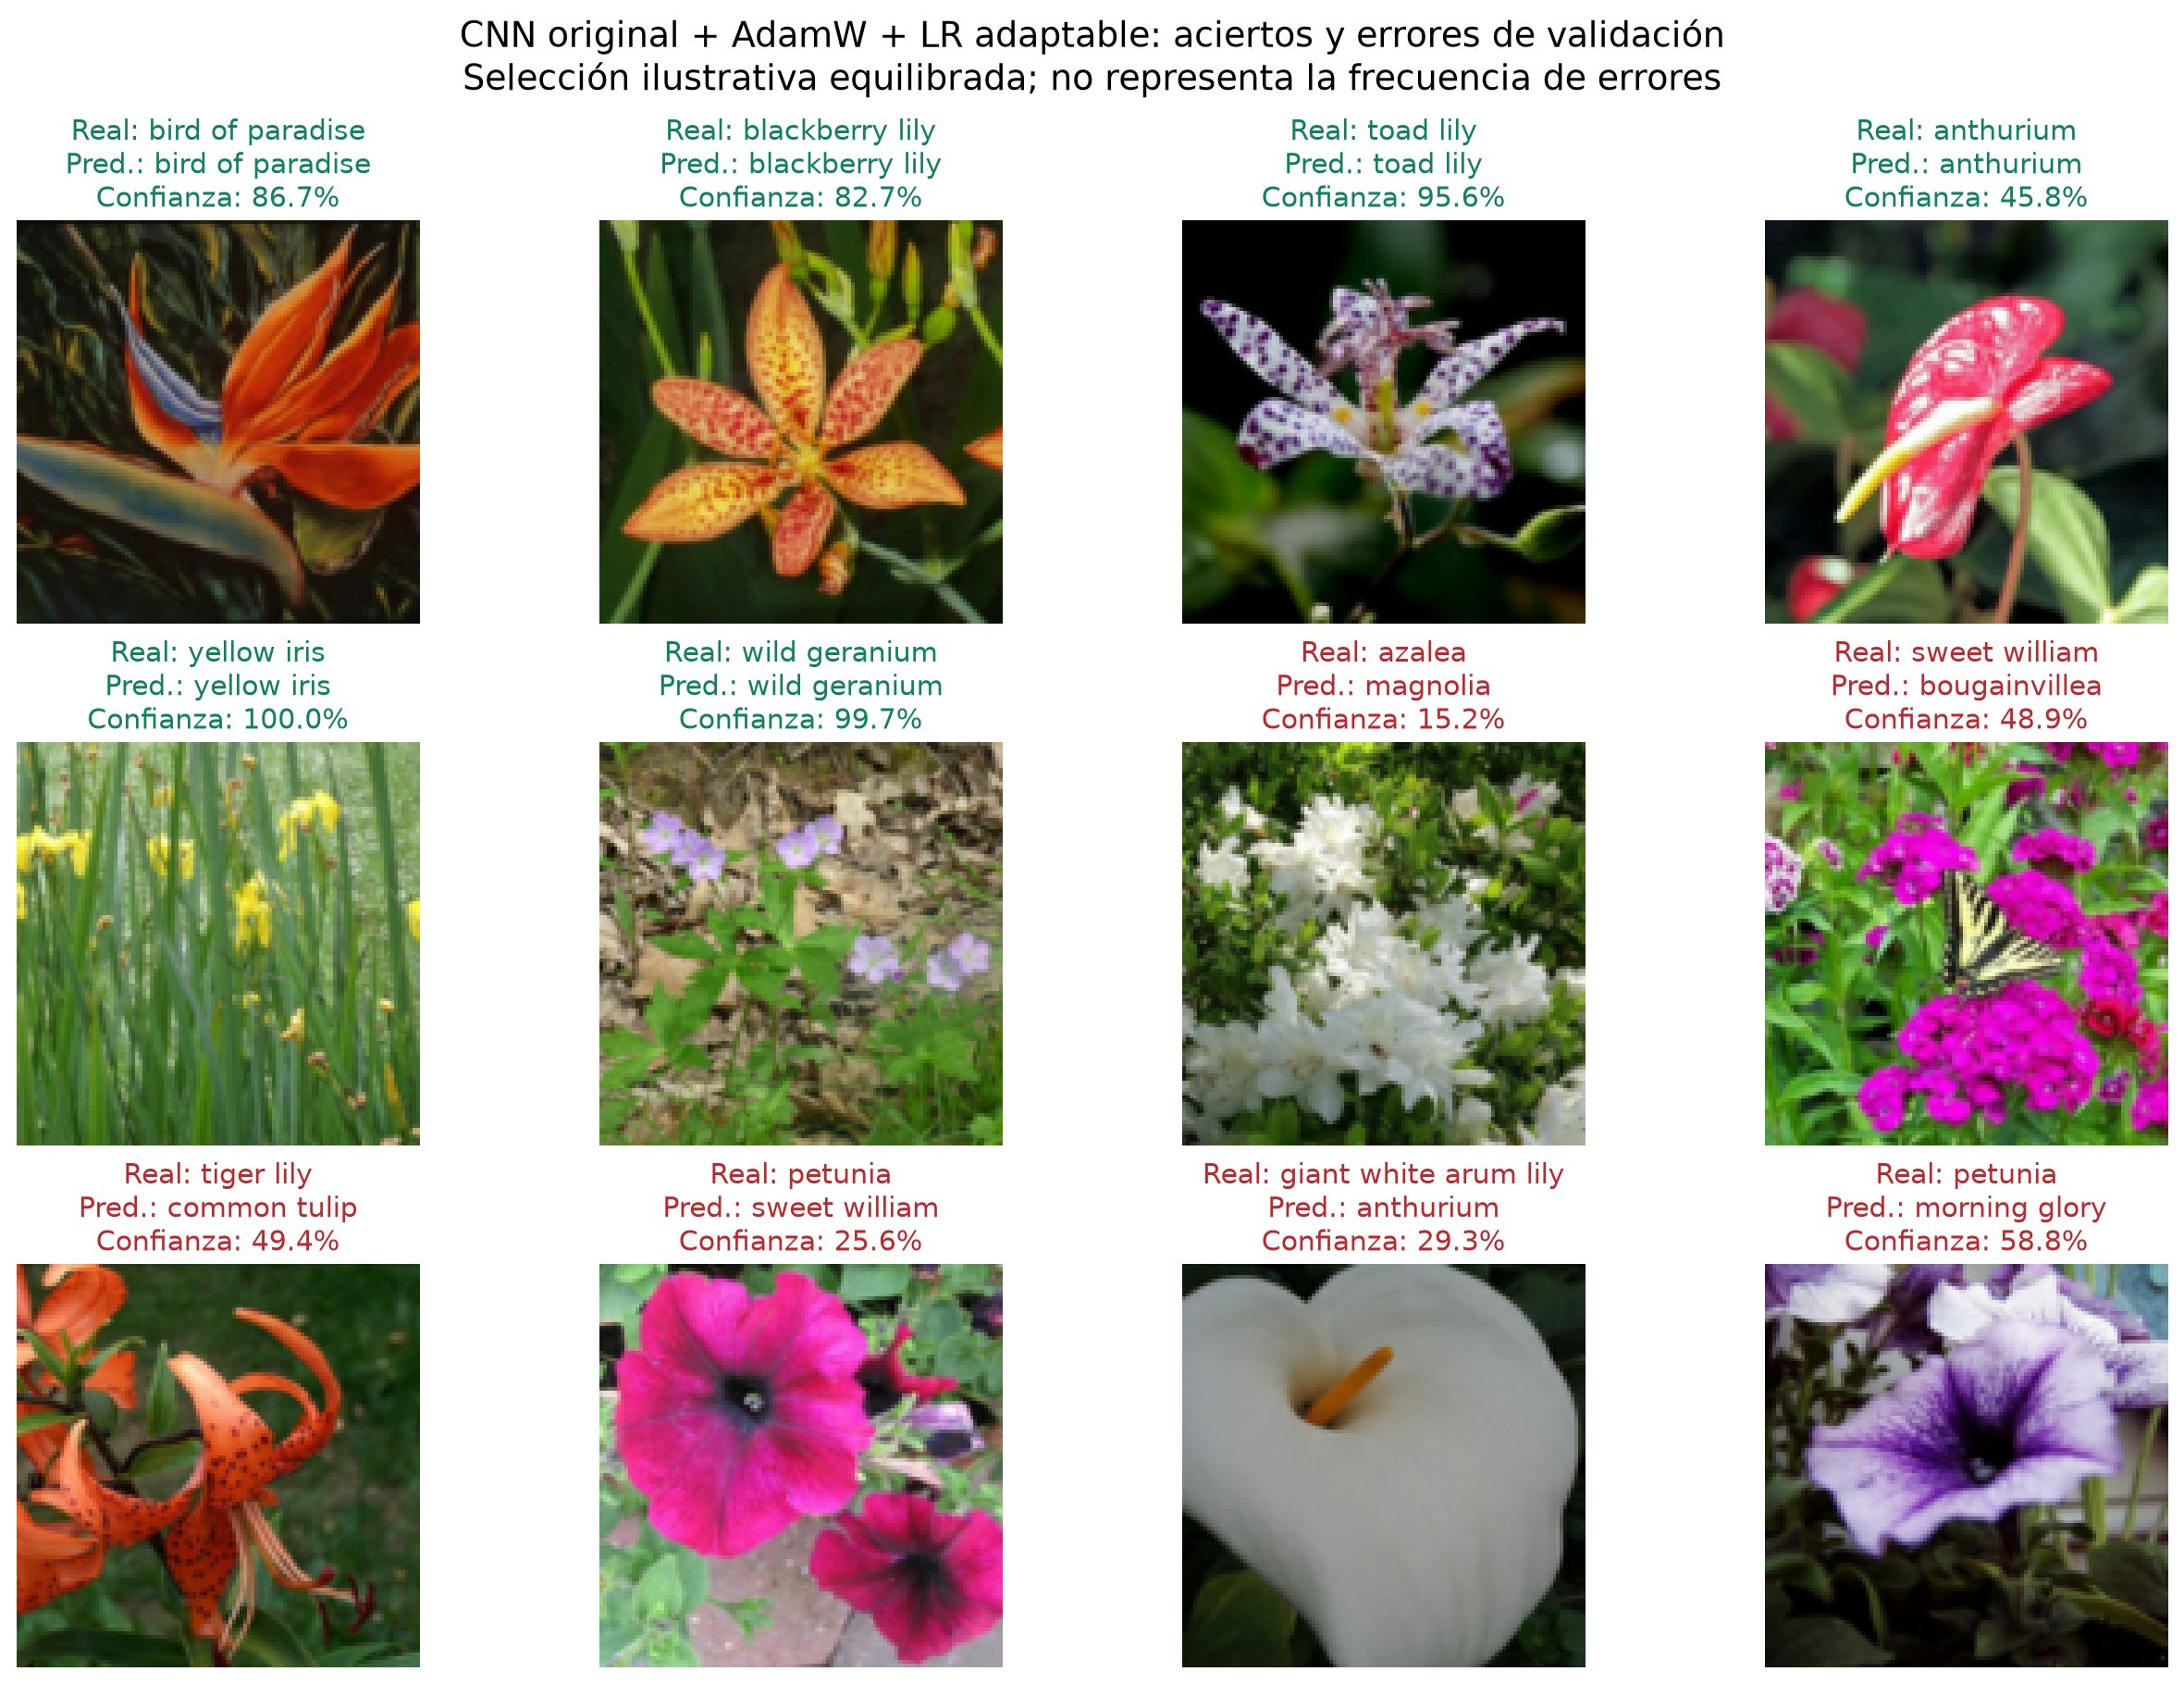

In [8]:
selected = results.sort_values("val_f1_macro", ascending=False).iloc[0]
key = selected.experiment
print("Modelo elegido:", selected.model, "| F1 macro:", selected.val_f1_macro, "| exactitud:", selected.val_accuracy)
run_dir = next((OUTPUT / "runs" / key).glob("*/summary.json")).parent
evaluation = json.loads((run_dir / "eval_report.json").read_text(encoding="utf-8"))
display(pd.DataFrame(evaluation["confused_pairs"]))
display(Image(filename=str(OUTPUT / "figures" / key / "confusion_matrix_normalized.png"), width=1100))
display(Image(filename=str(OUTPUT / "figures" / key / "predicciones_ejemplo.png"), width=1000))

## 7. Comprobación de las métricas y artefactos

Se recalculan exactitud y F1 desde las predicciones individuales, se comprueba que la matriz contiene 3,712 casos y se verifica que cada corrida tiene sus figuras. La evaluación también compara los logits del checkpoint de GPU y su exportación a Keras.

In [9]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
for row in results.itertuples():
    run_dir = next((OUTPUT / "runs" / row.experiment).glob("*/summary.json")).parent
    pred = pd.read_csv(run_dir / "evaluation/validation_predictions.csv")
    cm = pd.read_csv(run_dir / "evaluation/confusion_matrix.csv", index_col=0)
    np.testing.assert_allclose(accuracy_score(pred.true_label, pred.predicted_label), row.val_accuracy, atol=1e-9)
    np.testing.assert_allclose(f1_score(pred.true_label, pred.predicted_label, average="macro"), row.val_f1_macro, atol=0.000051)
    assert cm.to_numpy().sum() == len(pred) == 3712
    assert cm.shape == (104,104)
    for name in ["curvas_entrenamiento_validacion", "confusion_matrix", "confusion_matrix_normalized", "predicciones_ejemplo"]:
        assert (OUTPUT / "figures" / row.experiment / f"{name}.png").exists()
    print(row.model, "OK:", len(pred), "predicciones y matriz 104×104")

Totalmente conectada (referencia) OK: 3712 predicciones y matriz 104×104
CNN original (4 convoluciones) OK: 3712 predicciones y matriz 104×104
CNN ampliada (6 convoluciones) OK: 3712 predicciones y matriz 104×104


CNN original + AdamW + LR adaptable OK: 3712 predicciones y matriz 104×104


## 8. Conclusiones y entrega

La tabla y las curvas sustentan la elección por F1 macro. Las métricas corresponden a una semilla y al conjunto usado para seleccionar los modelos. No se atribuye a Avance 3 la referencia MLP reconstruida, ni a DM los resultados de entrenamiento con todas las imágenes reales.

Se corrigieron resolución, lote, descripción de arquitecturas, separación entre destilación y clasificación, selección del checkpoint y alcance de validación. Se incorporaron las representaciones solicitadas. No se afirma atender comentarios de retroalimentación cuyo texto no fue proporcionado.

El PDF actualizado contiene las secciones 1–8. Los archivos de entrega se llaman `equipo_proyecto_avance4.pdf` y `equipo_proyecto_avance4.ipynb`. Las figuras originales se conservan para reutilizarlas en la presentación.